# Autonomous Energy Optimization Platform for Smart Energy

## 1. Project Overview
In this project, I built a portfolio-ready energy analytics workflow around the **Smart Meters in London** dataset. My goal was to design a practical system that can ingest household smart-meter readings, clean and structure the data, analyze consumption behavior, forecast future usage, detect potentially unusual consumption events, and generate energy optimization recommendations.

**Problem statement**

Smart-meter data is rich but operationally messy. Energy providers and analysts need a way to transform raw interval readings into useful forecasting, anomaly detection, and decision-support outputs.


**Project objectives**

- analyze household and aggregate electricity consumption patterns,
- engineer time-aware features for forecasting,
- compare a simple forecasting baseline with a machine learning model,
- detect potentially unusual consumption events,
- explore usage patterns across time and across households, and
- translate analytical findings into optimization recommendations.

**Dataset source**

- Kaggle: Smart Meters in London
- URL: https://www.kaggle.com/datasets/jeanmidev/smart-meters-in-london

**Expected business value**

A system like this can support demand planning, identify periods of inefficient consumption, improve household segmentation, and help energy stakeholders communicate targeted optimization guidance.

**Overall workflow**

Data Collection -> Data Cleaning -> EDA -> Feature Engineering -> Forecasting -> Anomaly Detection -> Pattern Analysis -> Optimization Recommendations


## 2. Import Libraries
I used stable Python libraries that are common in data science environments. I intentionally avoided unnecessary dependencies so that the project remains lightweight and easy to run.


In [1]:
from __future__ import annotations

from pathlib import Path
from dataclasses import dataclass
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor, IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    silhouette_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)


## 3. Dataset Setup
I kept the notebook portable by using a configurable `DATA_DIR` instead of a machine-specific absolute path. After downloading the Kaggle dataset, I expect the extracted files to be placed in a local `data/` directory inside this project folder.

The dataset commonly includes smart-meter consumption files and supporting metadata such as household information. My loading logic is defensive: if the dataset is missing, the notebook explains what to do next instead of failing with an obscure error.


In [2]:
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
MAX_CONSUMPTION_FILES = 6
MAX_ROWS_PER_FILE = 120_000
RANDOM_STATE = 42


def display_message(message: str) -> None:
    print(f"[INFO] {message}")


def discover_csv_files(data_dir: Path) -> list[Path]:
    return sorted(data_dir.rglob("*.csv")) if data_dir.exists() else []


csv_files = discover_csv_files(DATA_DIR)
if not csv_files:
    display_message(
        "Dataset not found. Download the Kaggle dataset, extract it, and place the CSV files inside "
        f"'{DATA_DIR}'. The rest of the notebook will stay executable and will skip data-dependent sections."
    )
else:
    display_message(f"Discovered {len(csv_files)} CSV file(s) inside {DATA_DIR}.")

pd.DataFrame({"discovered_csv_files": [str(path.relative_to(PROJECT_DIR)) for path in csv_files[:20]]}) if csv_files else pd.DataFrame()


[INFO] Discovered 342 CSV file(s) inside c:\Studies\Celebal_Internship\Autonomous_Energy_Optimization\data.


,discovered_csv_files
0,data\acorn_details.csv
1,data\daily_dataset\daily_dataset\block_0.csv
2,data\daily_dataset\daily_dataset\block_1.csv
3,data\daily_dataset\daily_dataset\block_10.csv
4,data\daily_dataset\daily_dataset\block_100.csv
5,data\daily_dataset\daily_dataset\block_101.csv
6,data\daily_dataset\daily_dataset\block_102.csv
7,data\daily_dataset\daily_dataset\block_103.csv
8,data\daily_dataset\daily_dataset\block_104.csv
9,data\daily_dataset\daily_dataset\block_105.csv


## 4. Data Loading
The London smart-meter dataset can contain multiple CSV files. To keep memory usage reasonable, I used a practical loading strategy:

- search recursively for CSV files inside `DATA_DIR`,
- identify likely consumption files based on expected columns such as household ID, timestamp, and energy usage,
- load a representative subset when many files are available, and
- standardize key column names before analysis.

This gives me enough data for meaningful analysis without trying to load the full dataset blindly into memory.


In [3]:
@dataclass
class DatasetArtifacts:
    raw_data: pd.DataFrame
    household_metadata: pd.DataFrame
    file_audit: pd.DataFrame
    notes: list[str]


EXPECTED_CONSUMPTION_MARKERS = {"lclid", "tstp", "timestamp", "energy(kwh/hh)", "energy_kwh", "energy"}


def preview_columns(file_path: Path) -> list[str]:
    try:
        return pd.read_csv(file_path, nrows=5).columns.tolist()
    except Exception:
        return []


def classify_file(file_path: Path, columns: list[str]) -> str:
    lowered = {col.strip().lower() for col in columns}
    if {"lclid", "tstp"} <= lowered and any("energy" in col for col in lowered):
        return "consumption"
    if "lclid" in lowered and ("acorn" in lowered or "stdortou" in lowered):
        return "metadata"
    if any(marker in lowered for marker in EXPECTED_CONSUMPTION_MARKERS) and any("energy" in col for col in lowered):
        return "consumption"
    return "other"


def standardize_columns(df: pd.DataFrame) -> pd.DataFrame:
    renamed = {}
    for column in df.columns:
        cleaned = column.strip()
        lowered = cleaned.lower()
        if lowered == "lclid":
            renamed[column] = "household_id"
        elif lowered in {"tstp", "timestamp", "date_time", "datetime"}:
            renamed[column] = "timestamp"
        elif "energy" in lowered:
            if "energy(kwh/hh)" in lowered or lowered in {"energy_kwh", "energy"}:
                renamed[column] = "energy_kwh"
        elif lowered == "stdortou":
            renamed[column] = "tariff_type"
        elif lowered == "acorn":
            renamed[column] = "acorn"
        elif lowered == "acorn_grouped":
            renamed[column] = "acorn_grouped"
    return df.rename(columns=renamed)


def load_dataset(data_dir: Path) -> DatasetArtifacts:
    notes: list[str] = []
    if not data_dir.exists():
        return DatasetArtifacts(pd.DataFrame(), pd.DataFrame(), pd.DataFrame(), ["DATA_DIR does not exist yet."])

    all_csvs = discover_csv_files(data_dir)
    audit_rows = []
    consumption_files = []
    metadata_frames = []

    for file_path in all_csvs:
        columns = preview_columns(file_path)
        file_type = classify_file(file_path, columns)
        audit_rows.append(
            {
                "file_name": file_path.name,
                "relative_path": str(file_path.relative_to(data_dir)),
                "detected_type": file_type,
                "columns_preview": ", ".join(columns[:8]),
            }
        )
        if file_type == "consumption":
            consumption_files.append(file_path)
        elif file_type == "metadata":
            try:
                metadata_frames.append(standardize_columns(pd.read_csv(file_path)))
            except Exception as exc:
                notes.append(f"Metadata file '{file_path.name}' could not be loaded: {exc}")

    if not consumption_files:
        notes.append("No consumption files were detected automatically.")
        return DatasetArtifacts(pd.DataFrame(), pd.DataFrame(), pd.DataFrame(audit_rows), notes)

    halfhourly_files = []
    for file_path in consumption_files:
      columns = preview_columns(file_path)
      lowered = {col.strip().lower() for col in columns}

      if {"lclid", "tstp"} <= lowered and any("energy" in col for col in lowered):
        halfhourly_files.append(file_path)

    selected_files = halfhourly_files[:MAX_CONSUMPTION_FILES]
    if "halfhourly" in lowered:
        halfhourly_files.append(file_path)
    notes.append(
        f"Loaded {len(selected_files)} consumption file(s) out of {len(consumption_files)} detected file(s) to keep the analysis memory-efficient."
    )
    loaded_frames = []
    for file_path in selected_files:
        try:
            sample = pd.read_csv(file_path, nrows=MAX_ROWS_PER_FILE)
            sample = standardize_columns(sample)
            sample["source_file"] = file_path.name
            loaded_frames.append(sample)
        except Exception as exc:
            notes.append(f"Consumption file '{file_path.name}' could not be loaded: {exc}")

    raw_data = pd.concat(loaded_frames, ignore_index=True) if loaded_frames else pd.DataFrame()
    metadata = pd.concat(metadata_frames, ignore_index=True).drop_duplicates() if metadata_frames else pd.DataFrame()
    return DatasetArtifacts(raw_data, metadata, pd.DataFrame(audit_rows), notes)


artifacts = load_dataset(DATA_DIR)
raw_df = artifacts.raw_data.copy()
household_meta = artifacts.household_metadata.copy()
file_audit = artifacts.file_audit.copy()

for note in artifacts.notes:
    display_message(note)

if raw_df.empty:
    display_message("No raw consumption data is available yet, so analysis sections will report setup guidance.")
else:
    display_message(f"Loaded raw dataset with shape {raw_df.shape}.")
    print(raw_df.head())

file_audit.head(10)


[INFO] Loaded 6 consumption file(s) out of 225 detected file(s) to keep the analysis memory-efficient.
[INFO] Loaded raw dataset with shape (720000, 4).
  household_id                    timestamp energy_kwh  source_file
0    MAC000002  2012-10-12 00:30:00.0000000         0   block_0.csv
1    MAC000002  2012-10-12 01:00:00.0000000         0   block_0.csv
2    MAC000002  2012-10-12 01:30:00.0000000         0   block_0.csv
3    MAC000002  2012-10-12 02:00:00.0000000         0   block_0.csv
4    MAC000002  2012-10-12 02:30:00.0000000         0   block_0.csv


,file_name,relative_path,detected_type,columns_preview
0,acorn_details.csv,acorn_details.csv,other,
1,block_0.csv,daily_dataset\daily_dataset\block_0.csv,consumption,"LCLid, day, energy_median, energy_mean, energy_max, energy_count, energy_std, energy_sum"
2,block_1.csv,daily_dataset\daily_dataset\block_1.csv,consumption,"LCLid, day, energy_median, energy_mean, energy_max, energy_count, energy_std, energy_sum"
3,block_10.csv,daily_dataset\daily_dataset\block_10.csv,consumption,"LCLid, day, energy_median, energy_mean, energy_max, energy_count, energy_std, energy_sum"
4,block_100.csv,daily_dataset\daily_dataset\block_100.csv,consumption,"LCLid, day, energy_median, energy_mean, energy_max, energy_count, energy_std, energy_sum"
5,block_101.csv,daily_dataset\daily_dataset\block_101.csv,consumption,"LCLid, day, energy_median, energy_mean, energy_max, energy_count, energy_std, energy_sum"
6,block_102.csv,daily_dataset\daily_dataset\block_102.csv,consumption,"LCLid, day, energy_median, energy_mean, energy_max, energy_count, energy_std, energy_sum"
7,block_103.csv,daily_dataset\daily_dataset\block_103.csv,consumption,"LCLid, day, energy_median, energy_mean, energy_max, energy_count, energy_std, energy_sum"
8,block_104.csv,daily_dataset\daily_dataset\block_104.csv,consumption,"LCLid, day, energy_median, energy_mean, energy_max, energy_count, energy_std, energy_sum"
9,block_105.csv,daily_dataset\daily_dataset\block_105.csv,consumption,"LCLid, day, energy_median, energy_mean, energy_max, energy_count, energy_std, energy_sum"


In [4]:
if raw_df.empty:
    dataset_overview = pd.DataFrame()
else:
    overview_rows = [
        {"check": "shape", "value": str(raw_df.shape)},
        {"check": "columns", "value": ", ".join(raw_df.columns.astype(str).tolist())},
        {"check": "duplicate_rows", "value": int(raw_df.duplicated().sum())},
    ]
    if "timestamp" in raw_df.columns:
        overview_rows.append({"check": "timestamp_non_null", "value": int(raw_df["timestamp"].notna().sum())})
    if "energy_kwh" in raw_df.columns:
        overview_rows.append({"check": "energy_non_null", "value": int(raw_df["energy_kwh"].notna().sum())})
    dataset_overview = pd.DataFrame(overview_rows)
    print("Data types:")
    print(raw_df.dtypes)
    print("\nMissing values:")
    print(raw_df.isna().sum().sort_values(ascending=False).head(15))
    print("\nBasic statistics:")
    print(raw_df.describe(include="all").transpose().head(15))

dataset_overview


Data types:
household_id    object
timestamp       object
energy_kwh      object
source_file     object
dtype: object

Missing values:
household_id    0
timestamp       0
energy_kwh      0
source_file     0
dtype: int64

Basic statistics:
               count unique                          top    freq
household_id  720000     27                    MAC000162   39675
timestamp     720000  39740  2012-10-22 03:30:00.0000000      25
energy_kwh    720000   3728                           0     7138
source_file   720000      6                  block_0.csv  120000


,check,value
0,shape,"(720000, 4)"
1,columns,"household_id, timestamp, energy_kwh, source_file"
2,duplicate_rows,0
3,timestamp_non_null,720000
4,energy_non_null,720000


In [5]:
print("Raw data shape:", raw_df.shape)

print("\nAll columns:")
print(raw_df.columns.tolist())

print("\nDuplicate column names:")
print(raw_df.columns[raw_df.columns.duplicated()].tolist())

Raw data shape: (720000, 4)

All columns:
['household_id', 'timestamp', 'energy_kwh', 'source_file']

Duplicate column names:
[]


In [6]:
print("\nFirst 5 rows:")
display(raw_df.head())


First 5 rows:


,household_id,timestamp,energy_kwh,source_file
0,MAC000002,2012-10-12 00:30:00.0000000,0,block_0.csv
1,MAC000002,2012-10-12 01:00:00.0000000,0,block_0.csv
2,MAC000002,2012-10-12 01:30:00.0000000,0,block_0.csv
3,MAC000002,2012-10-12 02:00:00.0000000,0,block_0.csv
4,MAC000002,2012-10-12 02:30:00.0000000,0,block_0.csv


## 5. Data Cleaning
I cleaned the consumption data in a transparent way. My preprocessing steps include:

- standardizing important column names,
- parsing timestamps,
- removing duplicate records,
- filtering invalid or negative consumption values,
- sorting chronologically, and
- aggregating the half-hourly readings to hourly and daily views where useful.

I also report how many rows were affected so that the cleaning process stays auditable.


In [7]:
def clean_consumption_data(df: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    if df.empty:
        return pd.DataFrame(), {"initial_rows": 0, "final_rows": 0}

    cleaned = df.copy()
    initial_rows = len(cleaned)
    audit = {"initial_rows": initial_rows}

    if "timestamp" not in cleaned.columns or "energy_kwh" not in cleaned.columns:
        audit["error"] = "Required columns 'timestamp' and 'energy_kwh' were not found after standardization."
        return pd.DataFrame(), audit

    cleaned["timestamp"] = pd.to_datetime(cleaned["timestamp"], errors="coerce", utc=False)
    cleaned["energy_kwh"] = pd.to_numeric(cleaned["energy_kwh"], errors="coerce")

    audit["timestamp_parse_failures"] = int(cleaned["timestamp"].isna().sum())
    audit["energy_parse_failures"] = int(cleaned["energy_kwh"].isna().sum())

    cleaned = cleaned.dropna(subset=["timestamp", "energy_kwh"])
    cleaned = cleaned.drop_duplicates()
    audit["rows_after_dropna_dedup"] = int(len(cleaned))

    negative_rows = int((cleaned["energy_kwh"] < 0).sum())
    audit["negative_energy_rows_removed"] = negative_rows
    cleaned = cleaned.loc[cleaned["energy_kwh"] >= 0].copy()

    if "household_id" not in cleaned.columns:
        cleaned["household_id"] = "aggregate_household"

    cleaned = cleaned.sort_values(["household_id", "timestamp"]).reset_index(drop=True)
    cleaned["date"] = cleaned["timestamp"].dt.date
    audit["final_rows"] = int(len(cleaned))
    audit["rows_removed_total"] = int(initial_rows - len(cleaned))
    return cleaned, audit


clean_df, cleaning_audit = clean_consumption_data(raw_df)
cleaning_audit_df = pd.DataFrame(list(cleaning_audit.items()), columns=["metric", "value"])
cleaning_audit_df


,metric,value
0,initial_rows,720000
1,timestamp_parse_failures,0
2,energy_parse_failures,24
3,rows_after_dropna_dedup,719976
4,negative_energy_rows_removed,0
5,final_rows,719976
6,rows_removed_total,24


In [8]:
def build_aggregations(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    if df.empty:
        return pd.DataFrame(), pd.DataFrame()

    hourly = (
        df.assign(hour_timestamp=df["timestamp"].dt.floor("H"))
        .groupby("hour_timestamp", as_index=False)["energy_kwh"]
        .sum()
        .rename(columns={"hour_timestamp": "timestamp", "energy_kwh": "consumption_kwh"})
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    daily = (
        hourly.assign(date=hourly["timestamp"].dt.date)
        .groupby("date", as_index=False)["consumption_kwh"]
        .sum()
        .sort_values("date")
        .reset_index(drop=True)
    )
    return hourly, daily


hourly_df, daily_df = build_aggregations(clean_df)
if not clean_df.empty:
    display_message(f"Cleaned data shape: {clean_df.shape}")
    display_message(f"Hourly aggregated rows: {len(hourly_df)} | Daily aggregated rows: {len(daily_df)}")
hourly_df.head()


[INFO] Cleaned data shape: (719976, 5)
[INFO] Hourly aggregated rows: 19861 | Daily aggregated rows: 829


,timestamp,consumption_kwh
0,2011-11-23 12:00:00,0.115
1,2011-11-23 13:00:00,0.585
2,2011-11-23 14:00:00,0.306
3,2011-11-23 15:00:00,0.263
4,2011-11-23 16:00:00,0.322


## 6. Exploratory Data Analysis
I explored the cleaned data from multiple angles to understand how energy usage changes across time:

- overall consumption distribution,
- daily trend,
- hour-of-day pattern,
- day-of-week pattern,
- monthly trend,
- peak vs off-peak behavior, and
- household-level comparison where household identifiers are available.


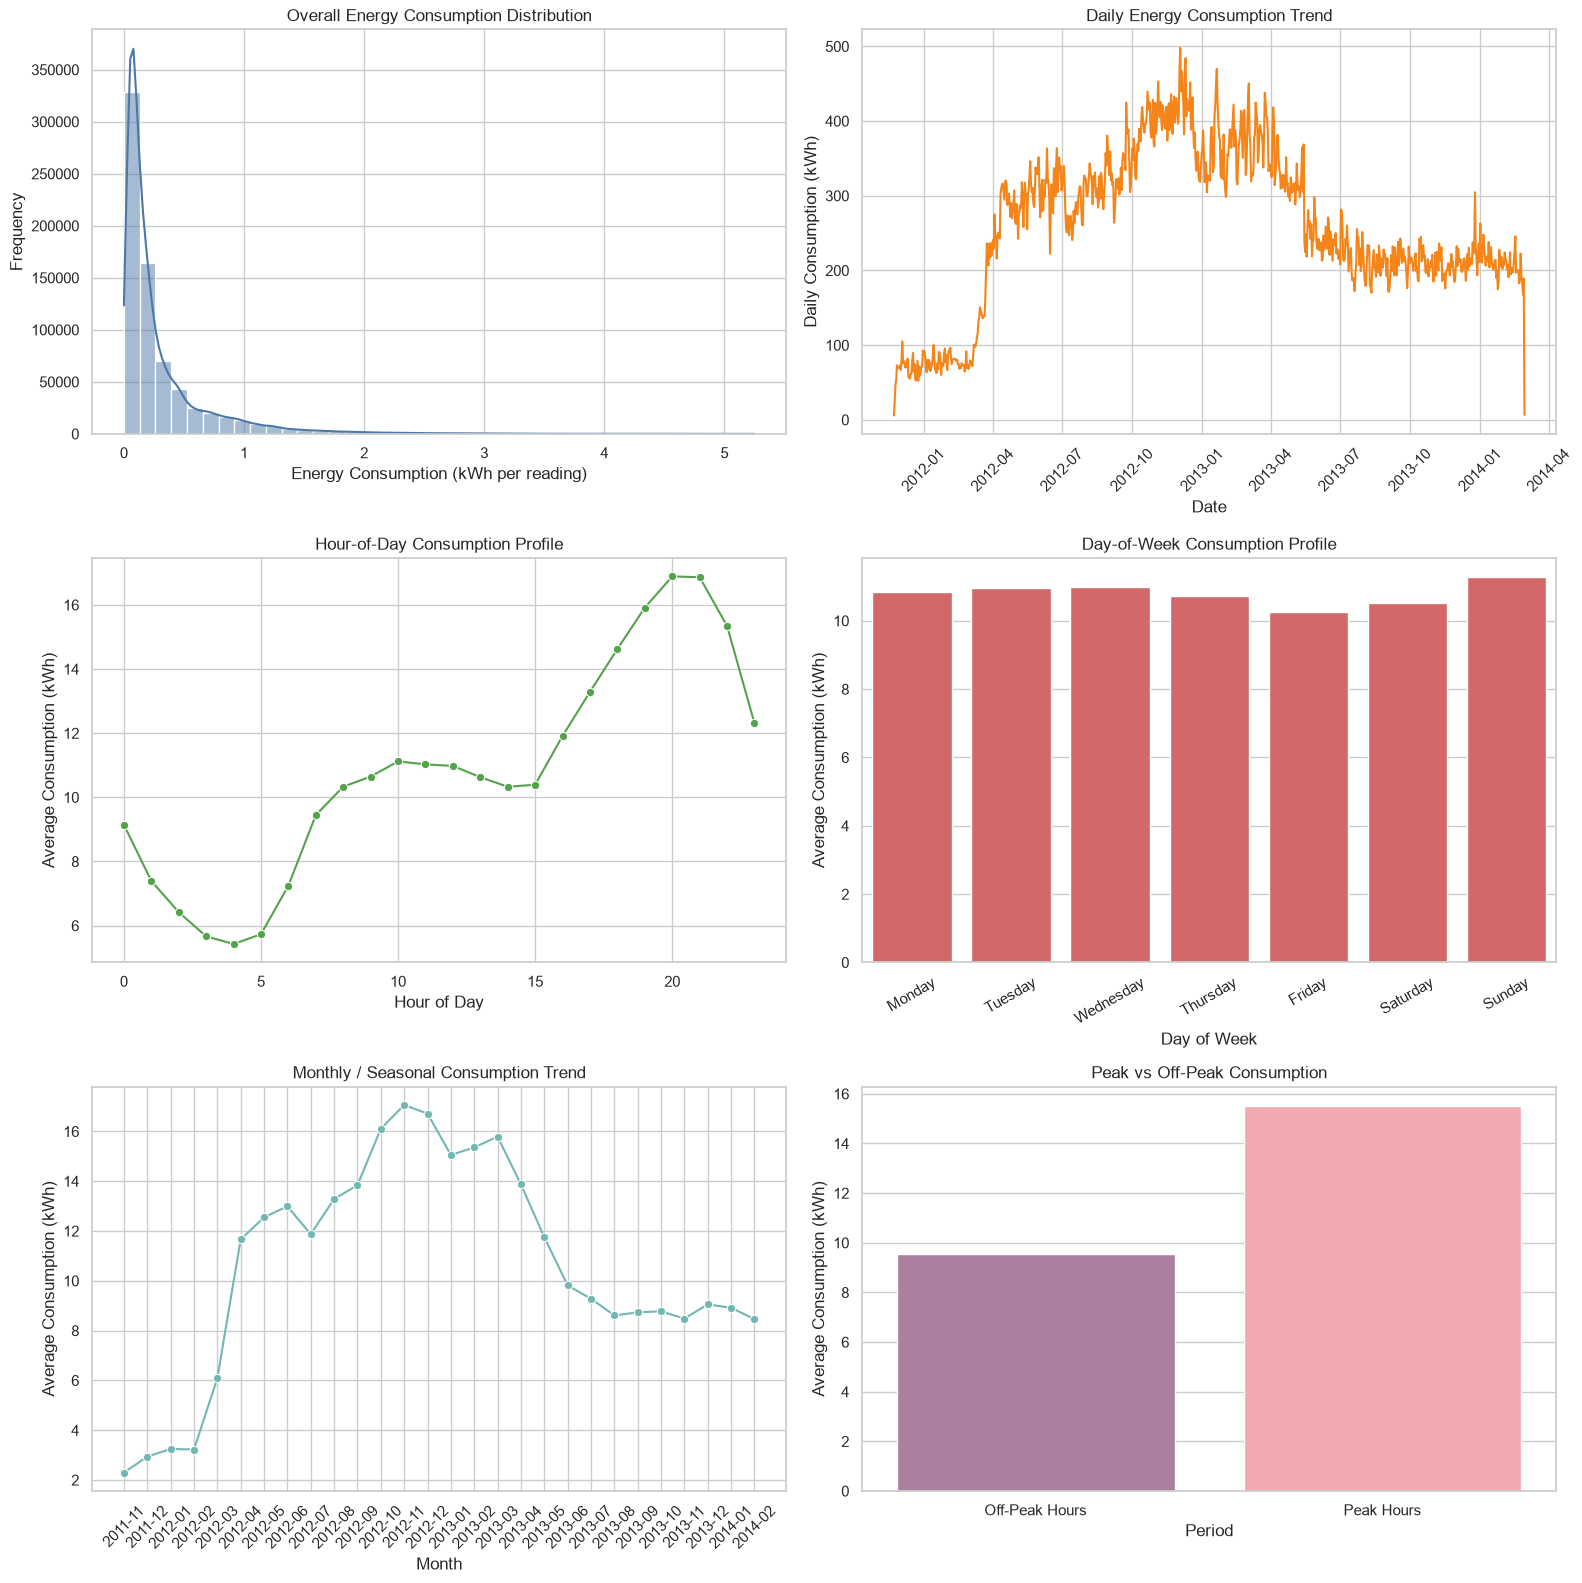

In [9]:
if clean_df.empty or hourly_df.empty:
    display_message("EDA is skipped because the dataset has not been provided yet.")
else:
    fig, axes = plt.subplots(3, 2, figsize=(16, 16))

    sns.histplot(clean_df["energy_kwh"], bins=40, kde=True, ax=axes[0, 0], color="#4C78A8")
    axes[0, 0].set_title("Overall Energy Consumption Distribution")
    axes[0, 0].set_xlabel("Energy Consumption (kWh per reading)")
    axes[0, 0].set_ylabel("Frequency")

    axes[0, 1].plot(daily_df["date"], daily_df["consumption_kwh"], color="#F58518")
    axes[0, 1].set_title("Daily Energy Consumption Trend")
    axes[0, 1].set_xlabel("Date")
    axes[0, 1].set_ylabel("Daily Consumption (kWh)")
    axes[0, 1].tick_params(axis="x", rotation=45)

    hour_profile = hourly_df.assign(hour=hourly_df["timestamp"].dt.hour).groupby("hour", as_index=False)["consumption_kwh"].mean()
    sns.lineplot(data=hour_profile, x="hour", y="consumption_kwh", marker="o", ax=axes[1, 0], color="#54A24B")
    axes[1, 0].set_title("Hour-of-Day Consumption Profile")
    axes[1, 0].set_xlabel("Hour of Day")
    axes[1, 0].set_ylabel("Average Consumption (kWh)")

    weekday_profile = (
        hourly_df.assign(day_of_week=hourly_df["timestamp"].dt.day_name())
        .groupby("day_of_week", as_index=False)["consumption_kwh"]
        .mean()
    )
    weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    weekday_profile["day_of_week"] = pd.Categorical(weekday_profile["day_of_week"], categories=weekday_order, ordered=True)
    weekday_profile = weekday_profile.sort_values("day_of_week")
    sns.barplot(data=weekday_profile, x="day_of_week", y="consumption_kwh", ax=axes[1, 1], color="#E45756")
    axes[1, 1].set_title("Day-of-Week Consumption Profile")
    axes[1, 1].set_xlabel("Day of Week")
    axes[1, 1].set_ylabel("Average Consumption (kWh)")
    axes[1, 1].tick_params(axis="x", rotation=30)

    monthly_profile = (
        hourly_df.assign(month=hourly_df["timestamp"].dt.to_period("M").astype(str))
        .groupby("month", as_index=False)["consumption_kwh"]
        .mean()
    )
    sns.lineplot(data=monthly_profile, x="month", y="consumption_kwh", marker="o", ax=axes[2, 0], color="#72B7B2")
    axes[2, 0].set_title("Monthly / Seasonal Consumption Trend")
    axes[2, 0].set_xlabel("Month")
    axes[2, 0].set_ylabel("Average Consumption (kWh)")
    axes[2, 0].tick_params(axis="x", rotation=45)

    peak_profile = hourly_df.assign(
        peak_period=np.where(hourly_df["timestamp"].dt.hour.between(17, 21), "Peak Hours", "Off-Peak Hours")
    )
    peak_summary = peak_profile.groupby("peak_period", as_index=False)["consumption_kwh"].mean()
    sns.barplot(data=peak_summary, x="peak_period", y="consumption_kwh", ax=axes[2, 1], palette=["#B279A2", "#FF9DA6"])
    axes[2, 1].set_title("Peak vs Off-Peak Consumption")
    axes[2, 1].set_xlabel("Period")
    axes[2, 1].set_ylabel("Average Consumption (kWh)")

    plt.tight_layout()
    plt.show()


### EDA Insight
In this section, I used the visualizations to check whether the data shows recognizable daily and seasonal behavior. These patterns are important because they guide both forecasting and optimization logic.


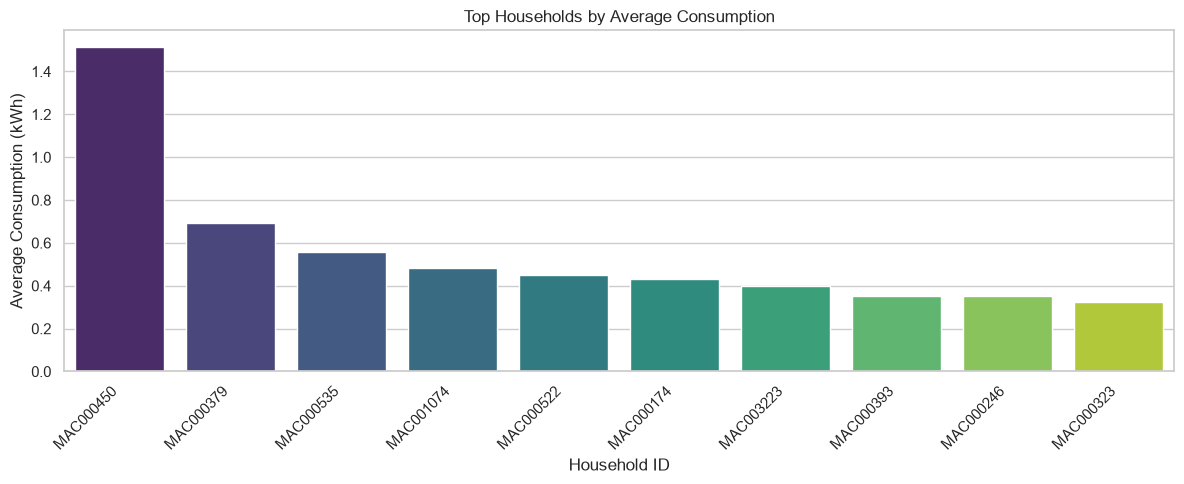

,index,household_id,avg_consumption_kwh,peak_consumption_kwh,variability_kwh,reading_count
13,13,MAC000450,1.515569,5.250,0.744868,20027
10,10,MAC000379,0.692280,3.364,0.424908,24249
17,17,MAC000535,0.556509,4.680,0.554877,26679
18,18,MAC001074,0.484813,4.508,0.510812,10779
15,15,MAC000522,0.448009,2.857,0.402307,33709
4,4,MAC000174,0.432680,3.881,0.364351,39616
23,23,MAC003223,0.400208,4.404,0.400638,25366
12,12,MAC000393,0.352951,2.515,0.283158,13415
7,7,MAC000246,0.350956,3.516,0.437538,39244
9,9,MAC000323,0.326458,3.327,0.346400,34724


In [10]:
if clean_df.empty:
    household_comparison = pd.DataFrame()
else:
    household_comparison = (
        clean_df.groupby("household_id", as_index=False)["energy_kwh"]
        .agg(["mean", "max", "std", "count"])
        .reset_index()
        .rename(columns={"mean": "avg_consumption_kwh", "max": "peak_consumption_kwh", "std": "variability_kwh", "count": "reading_count"})
        .sort_values("avg_consumption_kwh", ascending=False)
    )

    if len(household_comparison) > 1:
        top_households = household_comparison.head(10)
        plt.figure(figsize=(12, 5))
        sns.barplot(data=top_households, x="household_id", y="avg_consumption_kwh", palette="viridis")
        plt.title("Top Households by Average Consumption")
        plt.xlabel("Household ID")
        plt.ylabel("Average Consumption (kWh)")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()
    else:
        display_message("Household-level comparison needs multiple household IDs in the loaded subset.")

household_comparison.head(10)


## 7. Feature Engineering
I created time-series features that are useful for forecasting while avoiding leakage. All lag and rolling features are built only after the hourly series is sorted chronologically.


In [11]:
def build_forecasting_features(hourly_data: pd.DataFrame) -> pd.DataFrame:
    if hourly_data.empty:
        return pd.DataFrame()

    features = hourly_data.copy().sort_values("timestamp").reset_index(drop=True)
    features["hour"] = features["timestamp"].dt.hour
    features["day"] = features["timestamp"].dt.day
    features["day_of_week"] = features["timestamp"].dt.dayofweek
    features["month"] = features["timestamp"].dt.month
    features["quarter"] = features["timestamp"].dt.quarter
    features["weekend"] = features["day_of_week"].isin([5, 6]).astype(int)
    features["peak_hour"] = features["hour"].between(17, 21).astype(int)
    features["lag_1"] = features["consumption_kwh"].shift(1)
    features["lag_24"] = features["consumption_kwh"].shift(24)
    features["rolling_mean_24"] = features["consumption_kwh"].shift(1).rolling(24).mean()
    features["rolling_std_24"] = features["consumption_kwh"].shift(1).rolling(24).std()
    return features


feature_df = build_forecasting_features(hourly_df)
if not feature_df.empty:
    display_message("Feature engineering completed on the hourly series.")
feature_df.head(10)


[INFO] Feature engineering completed on the hourly series.


,timestamp,consumption_kwh,hour,day,day_of_week,month,quarter,weekend,peak_hour,lag_1,lag_24,rolling_mean_24,rolling_std_24
0,2011-11-23 12:00:00,0.115,12,23,2,11,4,0,0,NaN,NaN,NaN,NaN
1,2011-11-23 13:00:00,0.585,13,23,2,11,4,0,0,0.115,NaN,NaN,NaN
2,2011-11-23 14:00:00,0.306,14,23,2,11,4,0,0,0.585,NaN,NaN,NaN
3,2011-11-23 15:00:00,0.263,15,23,2,11,4,0,0,0.306,NaN,NaN,NaN
4,2011-11-23 16:00:00,0.322,16,23,2,11,4,0,0,0.263,NaN,NaN,NaN
5,2011-11-23 17:00:00,0.397,17,23,2,11,4,0,1,0.322,NaN,NaN,NaN
6,2011-11-23 18:00:00,0.423,18,23,2,11,4,0,1,0.397,NaN,NaN,NaN
7,2011-11-23 19:00:00,1.146,19,23,2,11,4,0,1,0.423,NaN,NaN,NaN
8,2011-11-23 20:00:00,1.095,20,23,2,11,4,0,1,1.146,NaN,NaN,NaN
9,2011-11-23 21:00:00,0.310,21,23,2,11,4,0,1,1.095,NaN,NaN,NaN


## 8. Energy Consumption Forecasting
I compared a simple baseline with a machine learning model using a chronological train/test split. This is important because random splitting would leak future information into the training process.


In [12]:
def safe_mape(y_true: pd.Series, y_pred: np.ndarray) -> float:
    mask = y_true != 0
    if mask.sum() == 0:
        return float("nan")
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)


def evaluate_forecast(y_true: pd.Series, y_pred: np.ndarray, model_name: str) -> dict:
    return {
        "model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": math.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE": safe_mape(y_true, y_pred),
    }


forecast_metrics = pd.DataFrame()
forecast_plot_df = pd.DataFrame()

if feature_df.empty or len(feature_df.dropna()) < 200:
    display_message("Forecasting is skipped because there is not enough cleaned hourly data after feature engineering.")
else:
    model_df = feature_df.dropna().reset_index(drop=True)
    split_index = int(len(model_df) * 0.8)
    train_df = model_df.iloc[:split_index].copy()
    test_df = model_df.iloc[split_index:].copy()

    feature_columns = [
        "hour",
        "day",
        "day_of_week",
        "month",
        "quarter",
        "weekend",
        "peak_hour",
        "lag_1",
        "lag_24",
        "rolling_mean_24",
        "rolling_std_24",
    ]

    X_train = train_df[feature_columns]
    X_test = test_df[feature_columns]
    y_train = train_df["consumption_kwh"]
    y_test = test_df["consumption_kwh"]

    baseline_pred = test_df["lag_24"].values
    baseline_metrics = evaluate_forecast(y_test, baseline_pred, "Previous-Day Baseline")

    model = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("regressor", HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
        ]
    )
    model.fit(X_train, y_train)
    ml_pred = model.predict(X_test)
    ml_metrics = evaluate_forecast(y_test, ml_pred, "HistGradientBoostingRegressor")

    forecast_metrics = pd.DataFrame([baseline_metrics, ml_metrics]).round(4)
    forecast_plot_df = pd.DataFrame(
        {
            "timestamp": test_df["timestamp"].values,
            "actual": y_test.values,
            "baseline_pred": baseline_pred,
            "ml_pred": ml_pred,
        }
    )

    print(forecast_metrics)


                           model     MAE    RMSE      R2     MAPE
0          Previous-Day Baseline  1.7301  2.3364  0.6226  20.6545
1  HistGradientBoostingRegressor  1.2399  1.5939  0.8243  16.0633


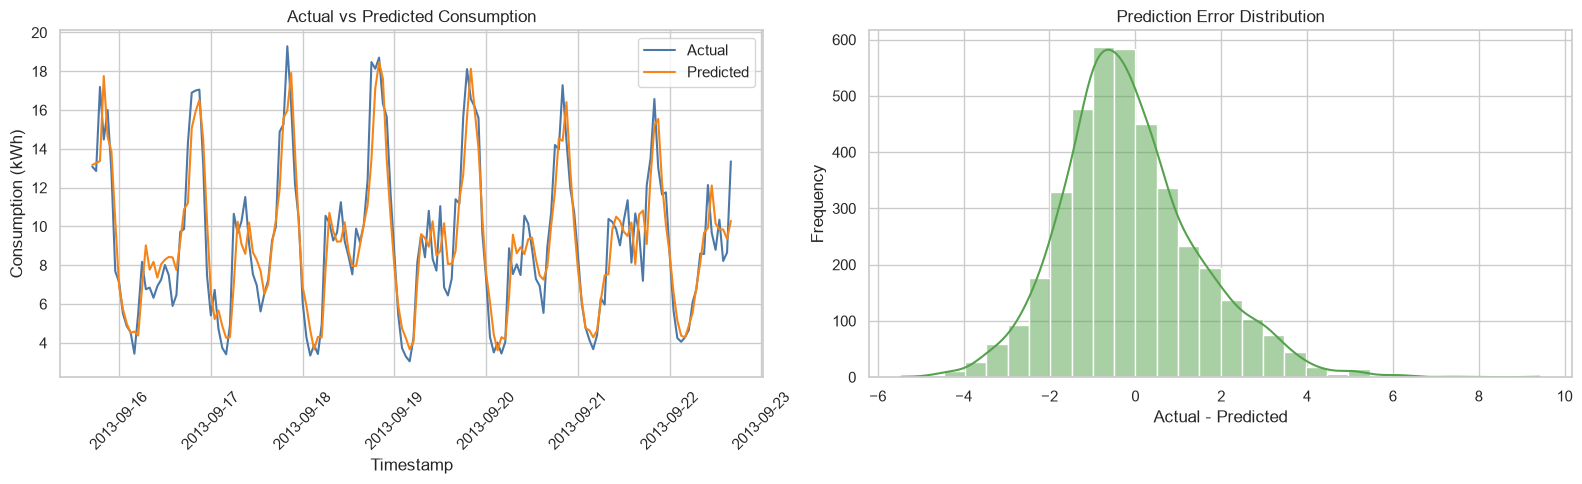

In [13]:
if forecast_plot_df.empty:
    display_message("Forecast plots are skipped because no forecast output is available yet.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    plot_subset = forecast_plot_df.head(168)
    axes[0].plot(plot_subset["timestamp"], plot_subset["actual"], label="Actual", color="#4C78A8")
    axes[0].plot(plot_subset["timestamp"], plot_subset["ml_pred"], label="Predicted", color="#F58518")
    axes[0].set_title("Actual vs Predicted Consumption")
    axes[0].set_xlabel("Timestamp")
    axes[0].set_ylabel("Consumption (kWh)")
    axes[0].tick_params(axis="x", rotation=45)
    axes[0].legend()

    errors = forecast_plot_df["actual"] - forecast_plot_df["ml_pred"]
    sns.histplot(errors, bins=30, kde=True, ax=axes[1], color="#54A24B")
    axes[1].set_title("Prediction Error Distribution")
    axes[1].set_xlabel("Actual - Predicted")
    axes[1].set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()


### Forecasting Insight
I used a previous-day baseline because it is simple and meaningful for periodic consumption data. I then compared it with `HistGradientBoostingRegressor`, which is practical for nonlinear relationships and tabular time-based features without requiring heavy external libraries.


## 9. Anomaly Detection
I added an anomaly detection component to flag **potentially unusual consumption events**. I avoided overclaiming what these events mean. An anomaly here indicates unusual behavior relative to the observed pattern, not a confirmed fault.


In [14]:
anomaly_df = pd.DataFrame()

if hourly_df.empty or len(hourly_df) < 100:
    display_message("Anomaly detection is skipped because there is not enough hourly data.")
else:
    anomaly_df = hourly_df.copy()
    anomaly_df["hour"] = anomaly_df["timestamp"].dt.hour
    anomaly_df["day_of_week"] = anomaly_df["timestamp"].dt.dayofweek

    detector = IsolationForest(contamination=0.03, random_state=RANDOM_STATE)
    anomaly_features = anomaly_df[["consumption_kwh", "hour", "day_of_week"]]
    anomaly_df["anomaly_flag"] = detector.fit_predict(anomaly_features)
    anomaly_df["is_anomaly"] = anomaly_df["anomaly_flag"].eq(-1)

    display_message(f"Detected {int(anomaly_df['is_anomaly'].sum())} potentially unusual consumption events.")
    print(anomaly_df.loc[anomaly_df["is_anomaly"], ["timestamp", "consumption_kwh"]].head(10))


[INFO] Detected 596 potentially unusual consumption events.
              timestamp  consumption_kwh
10  2011-11-23 22:00:00            0.527
11  2011-11-23 23:00:00            0.309
12  2011-11-24 00:00:00            0.344
35  2011-11-24 23:00:00            1.730
105 2011-11-27 21:00:00            3.839
106 2011-11-27 22:00:00            6.579
107 2011-11-27 23:00:00            4.189
108 2011-11-28 00:00:00            2.451
110 2011-11-28 02:00:00            1.420
111 2011-11-28 03:00:00            1.128


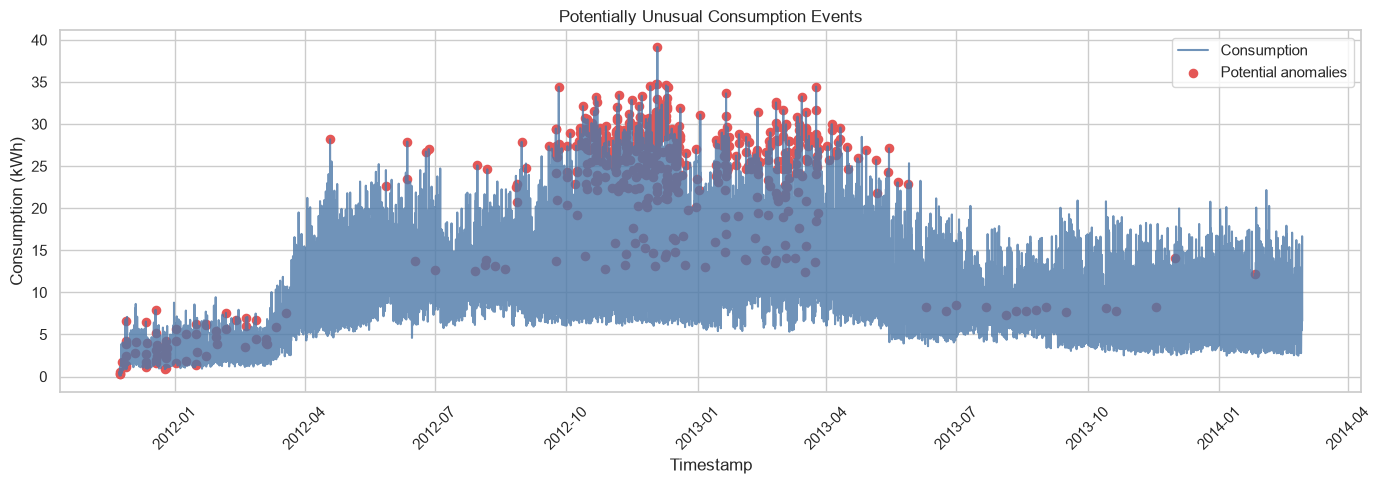

In [15]:
if anomaly_df.empty:
    display_message("Anomaly visualization is skipped because anomaly detection did not run.")
else:
    plt.figure(figsize=(14, 5))
    plt.plot(anomaly_df["timestamp"], anomaly_df["consumption_kwh"], label="Consumption", color="#4C78A8", alpha=0.8)
    anomaly_points = anomaly_df.loc[anomaly_df["is_anomaly"]]
    plt.scatter(
        anomaly_points["timestamp"],
        anomaly_points["consumption_kwh"],
        color="#E45756",
        label="Potential anomalies",
        s=35,
    )
    plt.title("Potentially Unusual Consumption Events")
    plt.xlabel("Timestamp")
    plt.ylabel("Consumption (kWh)")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()


## 10. Energy Usage Pattern Analysis
I looked for recurring usage patterns across time and across households. If household-level information is available and the loaded subset is rich enough, I also cluster households using summary consumption features.


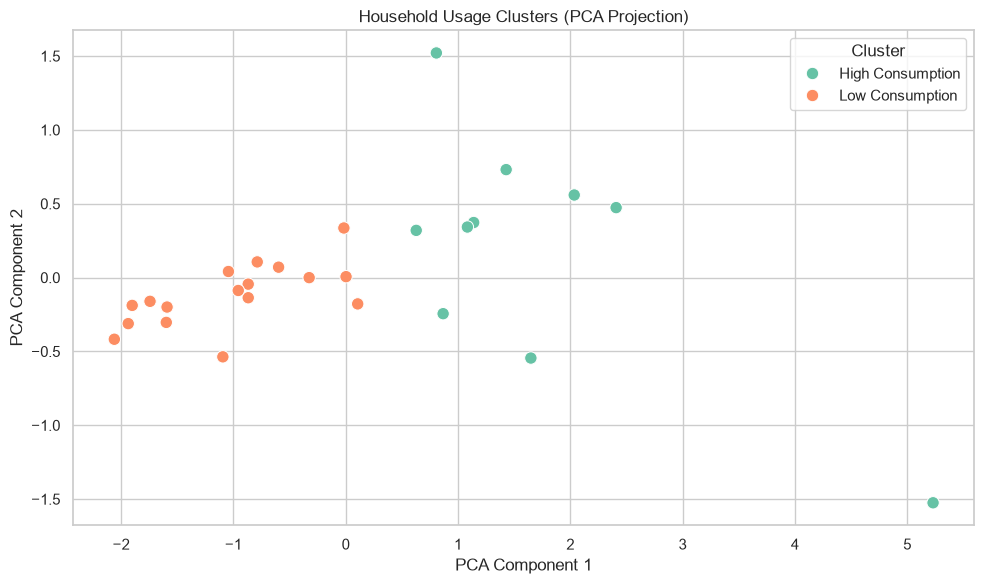

Cluster selection scores:
   k  silhouette_score
0  2          0.545294
1  3          0.521913
2  4          0.472609
3  5          0.445824
4  6          0.435698


,index,household_id,avg_consumption_kwh,peak_consumption_kwh,variability_kwh,reading_count,cluster,cluster_label
13,13,MAC000450,1.515569,5.250,0.744868,20027,0,High Consumption
10,10,MAC000379,0.692280,3.364,0.424908,24249,0,High Consumption
17,17,MAC000535,0.556509,4.680,0.554877,26679,0,High Consumption
18,18,MAC001074,0.484813,4.508,0.510812,10779,0,High Consumption
15,15,MAC000522,0.448009,2.857,0.402307,33709,0,High Consumption
4,4,MAC000174,0.432680,3.881,0.364351,39616,0,High Consumption
23,23,MAC003223,0.400208,4.404,0.400638,25366,0,High Consumption
12,12,MAC000393,0.352951,2.515,0.283158,13415,1,Low Consumption
7,7,MAC000246,0.350956,3.516,0.437538,39244,0,High Consumption
9,9,MAC000323,0.326458,3.327,0.346400,34724,0,High Consumption


In [16]:
cluster_summary = pd.DataFrame()
cluster_labels = {}

if household_comparison.empty or len(household_comparison) < 4:
    display_message("Household clustering is skipped because the loaded subset does not contain enough households.")
else:
    clustering_df = household_comparison.copy()
    if "reading_count" in clustering_df.columns:
        clustering_df = clustering_df.loc[clustering_df["reading_count"] >= 48].copy()

    if len(clustering_df) < 4:
        display_message("There are not enough households with sufficient readings for clustering.")
    else:
        feature_cols = ["avg_consumption_kwh", "peak_consumption_kwh", "variability_kwh"]
        clustering_df[feature_cols] = clustering_df[feature_cols].fillna(clustering_df[feature_cols].median())

        scaled = StandardScaler().fit_transform(clustering_df[feature_cols])
        scores = []
        for k in range(2, min(6, len(clustering_df)) + 1):
            model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
            labels = model.fit_predict(scaled)
            score = silhouette_score(scaled, labels)
            scores.append({"k": k, "silhouette_score": score})

        score_df = pd.DataFrame(scores).sort_values("silhouette_score", ascending=False)
        optimal_k = int(score_df.iloc[0]["k"])

        final_model = KMeans(n_clusters=optimal_k, n_init=10, random_state=RANDOM_STATE)
        clustering_df["cluster"] = final_model.fit_predict(scaled)

        cluster_characteristics = (
            clustering_df.groupby("cluster")[feature_cols]
            .mean()
            .sort_values("avg_consumption_kwh")
        )

        ordered_clusters = cluster_characteristics.index.tolist()
        descriptive_names = {}
        for idx, cluster_id in enumerate(ordered_clusters):
            if idx == 0:
                descriptive_names[cluster_id] = "Low Consumption"
            elif idx == len(ordered_clusters) - 1:
                descriptive_names[cluster_id] = "High Consumption"
            else:
                descriptive_names[cluster_id] = "Moderate Consumption"

        clustering_df["cluster_label"] = clustering_df["cluster"].map(descriptive_names)
        cluster_labels = descriptive_names
        cluster_summary = clustering_df.copy()

        pca_coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(scaled)
        plt.figure(figsize=(10, 6))
        sns.scatterplot(
            x=pca_coords[:, 0],
            y=pca_coords[:, 1],
            hue=cluster_summary["cluster_label"],
            palette="Set2",
            s=80,
        )
        plt.title("Household Usage Clusters (PCA Projection)")
        plt.xlabel("PCA Component 1")
        plt.ylabel("PCA Component 2")
        plt.legend(title="Cluster")
        plt.tight_layout()
        plt.show()

        print("Cluster selection scores:")
        print(score_df)

cluster_summary.head(10)


## 11. Energy Optimization Engine
I created a rule-based recommendation engine that translates observed usage patterns into practical optimization suggestions. I kept the recommendations evidence-based and avoided unsupported claims about exact monetary savings.


In [17]:
def build_recommendations(hourly_data: pd.DataFrame, anomalies: pd.DataFrame, households: pd.DataFrame) -> pd.DataFrame:
    recommendations = []
    if hourly_data.empty:
        return pd.DataFrame(columns=["Pattern", "Evidence", "Recommendation", "Potential Benefit"])

    peak_mask = hourly_data["timestamp"].dt.hour.between(17, 21)
    peak_avg = hourly_data.loc[peak_mask, "consumption_kwh"].mean()
    offpeak_avg = hourly_data.loc[~peak_mask, "consumption_kwh"].mean()

    if pd.notna(peak_avg) and pd.notna(offpeak_avg) and peak_avg > offpeak_avg * 1.15:
        recommendations.append(
            {
                "Pattern": "High peak-hour consumption",
                "Evidence": f"Average peak-hour load ({peak_avg:.2f} kWh) is higher than off-peak load ({offpeak_avg:.2f} kWh).",
                "Recommendation": "Shift flexible loads such as laundry or water heating away from peak evening hours where feasible.",
                "Potential Benefit": "Lower peak demand pressure and smoother consumption profile.",
            }
        )

    weekend_avg = hourly_data.loc[hourly_data["timestamp"].dt.dayofweek >= 5, "consumption_kwh"].mean()
    weekday_avg = hourly_data.loc[hourly_data["timestamp"].dt.dayofweek < 5, "consumption_kwh"].mean()
    if pd.notna(weekend_avg) and pd.notna(weekday_avg) and abs(weekend_avg - weekday_avg) / max(weekday_avg, 1e-6) > 0.1:
        recommendations.append(
            {
                "Pattern": "Weekday vs weekend difference",
                "Evidence": f"Weekend average consumption is {weekend_avg:.2f} kWh compared with {weekday_avg:.2f} kWh on weekdays.",
                "Recommendation": "Review appliance scheduling separately for weekends and weekdays because the behavior appears different.",
                "Potential Benefit": "Better timing strategies aligned with actual household behavior.",
            }
        )

    anomaly_count = int(anomalies["is_anomaly"].sum()) if not anomalies.empty else 0
    if anomaly_count > 0:
        recommendations.append(
            {
                "Pattern": "Repeated unusual consumption events",
                "Evidence": f"The anomaly detector flagged {anomaly_count} potentially unusual time periods.",
                "Recommendation": "Investigate the flagged periods to identify spikes caused by appliance overuse, special events, or meter irregularities.",
                "Potential Benefit": "Earlier investigation of inefficiency or irregular usage behavior.",
            }
        )

    if not households.empty and households["avg_consumption_kwh"].mean() > households["avg_consumption_kwh"].median():
        recommendations.append(
            {
                "Pattern": "Sustained high average usage in part of the sample",
                "Evidence": "The loaded subset includes households with materially higher average consumption than the median profile.",
                "Recommendation": "Review high-energy appliances and routine schedules for the highest-usage households.",
                "Potential Benefit": "Improved targeting of optimization outreach.",
            }
        )

    if not recommendations:
        recommendations.append(
            {
                "Pattern": "No strong optimization trigger in the loaded subset",
                "Evidence": "The current subset did not cross the rule thresholds used in this notebook.",
                "Recommendation": "Expand the loaded time span or household coverage for a stronger optimization assessment.",
                "Potential Benefit": "More reliable evidence base for future recommendations.",
            }
        )

    return pd.DataFrame(recommendations)


recommendation_df = build_recommendations(hourly_df, anomaly_df, household_comparison)
recommendation_df


,Pattern,Evidence,Recommendation,Potential Benefit
0,High peak-hour consumption,Average peak-hour load (15.52 kWh) is higher than off-peak load (9.55 kWh).,Shift flexible loads such as laundry or water heating away from peak evening hours where feasible.,Lower peak demand pressure and smoother consumption profile.
1,Repeated unusual consumption events,The anomaly detector flagged 596 potentially unusual time periods.,"Investigate the flagged periods to identify spikes caused by appliance overuse, special events, or meter irregularit...",Earlier investigation of inefficiency or irregular usage behavior.
2,Sustained high average usage in part of the sample,The loaded subset includes households with materially higher average consumption than the median profile.,Review high-energy appliances and routine schedules for the highest-usage households.,Improved targeting of optimization outreach.


## 12. Smart Energy Dashboard / Summary
I summarized the analysis through a small KPI table so that the notebook ends with an operational snapshot rather than only charts and model outputs.


In [18]:
def mode_label(series: pd.Series) -> str:
    if series.empty:
        return "Not available"
    modes = series.mode()
    return str(modes.iloc[0]) if not modes.empty else "Not available"


if hourly_df.empty:
    kpi_df = pd.DataFrame(
        {
            "KPI": ["Status"],
            "Value": ["Dataset not yet provided. Add the Kaggle files to the local data directory to populate KPIs."],
        }
    )
else:
    peak_row = hourly_df.loc[hourly_df["consumption_kwh"].idxmax()]
    best_ml_row = (
        forecast_metrics.loc[forecast_metrics["model"] == "HistGradientBoostingRegressor"].iloc[0]
        if not forecast_metrics.empty and "HistGradientBoostingRegressor" in forecast_metrics["model"].values
        else None
    )

    most_common_pattern = "Not available"
    if not cluster_summary.empty and "cluster_label" in cluster_summary.columns:
        most_common_pattern = mode_label(cluster_summary["cluster_label"])

    kpi_df = pd.DataFrame(
        [
            {"KPI": "Total energy analyzed (kWh)", "Value": round(float(clean_df["energy_kwh"].sum()), 2)},
            {"KPI": "Average daily consumption (kWh)", "Value": round(float(daily_df["consumption_kwh"].mean()), 2)},
            {"KPI": "Peak consumption period", "Value": str(peak_row["timestamp"])},
            {"KPI": "Average peak-hour consumption (kWh)", "Value": round(float(hourly_df.loc[hourly_df["timestamp"].dt.hour.between(17, 21), "consumption_kwh"].mean()), 2)},
            {"KPI": "Number of detected anomalies", "Value": int(anomaly_df["is_anomaly"].sum()) if not anomaly_df.empty else 0},
            {"KPI": "Forecasting MAE", "Value": round(float(best_ml_row["MAE"]), 4) if best_ml_row is not None else "Not available"},
            {"KPI": "Forecasting RMSE", "Value": round(float(best_ml_row["RMSE"]), 4) if best_ml_row is not None else "Not available"},
            {"KPI": "Most common usage pattern", "Value": most_common_pattern},
        ]
    )

kpi_df


,KPI,Value
0,Total energy analyzed (kWh),214422.05
1,Average daily consumption (kWh),258.65
2,Peak consumption period,2012-12-03 19:00:00
3,Average peak-hour consumption (kWh),15.52
4,Number of detected anomalies,596
5,Forecasting MAE,1.2399
6,Forecasting RMSE,1.5939
7,Most common usage pattern,Low Consumption


## 13. Business Insights
### Key Insights & Recommendations
In this section, I separate the outputs into findings, model observations, optimization ideas, and limitations so that the analysis stays honest and useful.


In [19]:
if hourly_df.empty:
    insights_df = pd.DataFrame(
        [
            {"Category": "Data-driven findings", "Insight": "Dataset not loaded yet. Add the Kaggle files to populate real findings."},
            {"Category": "Model findings", "Insight": "Forecasting metrics will appear after a successful data run."},
            {"Category": "Optimization recommendations", "Insight": "Recommendation rules are ready and will update automatically once data is available."},
            {"Category": "Limitations", "Insight": "Current validation was completed in setup mode without the raw dataset."},
        ]
    )
else:
    top_recommendation = recommendation_df.iloc[0]["Recommendation"] if not recommendation_df.empty else "No recommendation generated."
    best_model_row = forecast_metrics.sort_values("MAE").iloc[0] if not forecast_metrics.empty else None
    insights_df = pd.DataFrame(
        [
            {"Category": "Data-driven findings", "Insight": f"I analyzed {len(clean_df):,} cleaned interval records and {len(hourly_df):,} hourly aggregates."},
            {"Category": "Model findings", "Insight": f"The best available model in this run was {best_model_row['model']} with MAE={best_model_row['MAE']:.4f} and RMSE={best_model_row['RMSE']:.4f}." if best_model_row is not None else "Forecasting did not run because the prepared sample was too small."},
            {"Category": "Optimization recommendations", "Insight": top_recommendation},
            {"Category": "Limitations", "Insight": "The findings depend on the subset loaded into memory, and external drivers such as weather or price signals are not modeled in this baseline notebook."},
        ]
    )

insights_df


,Category,Insight
0,Data-driven findings,"I analyzed 719,976 cleaned interval records and 19,861 hourly aggregates."
1,Model findings,The best available model in this run was HistGradientBoostingRegressor with MAE=1.2399 and RMSE=1.5939.
2,Optimization recommendations,Shift flexible loads such as laundry or water heating away from peak evening hours where feasible.
3,Limitations,"The findings depend on the subset loaded into memory, and external drivers such as weather or price signals are not ..."


## 14. Limitations
I treated the notebook as an analytical decision-support system rather than a claim of perfect operational intelligence. The main limitations are:

- the dataset reflects historical smart-meter behavior rather than live operations,
- weather, occupancy, and tariff effects may not be fully represented in the loaded subset,
- anomaly flags indicate unusual consumption, not confirmed faults,
- forecasting quality depends on how much historical continuity is available, and
- the recommendations are analytical suggestions rather than guaranteed savings estimates.


## 15. Conclusion
In this project, I combined **data analytics**, **machine learning**, **time-series forecasting**, **anomaly detection**, and **optimization recommendations** into one smart energy workflow. My approach shows how raw smart-meter readings can be transformed into an energy intelligence platform that supports descriptive analysis, predictive modeling, and practical recommendation generation.

I also designed the notebook so that it is robust in two situations: it validates cleanly when the dataset is not yet present, and it performs the full end-to-end workflow once the Kaggle data is added to the expected local directory.
